# Interactive tutorial: OMD on the beach bar

This notebook solves a small stationary mean field game with **Online Mirror Descent (OMD)**,
using only the public `benchmfg` API.

The environment is the **Lasry-Lions chain**, a 1D version of the *beach bar* problem.
Agents stand on a chain of states and the bar is in the middle. Each agent wants to be
near the bar (`center_attraction`) but dislikes crowds (`crowd_penalty_coefficient`)
and pays a cost to move (`movement_penalty`). The actions are left, stay and right.

You can run it locally with `pip install bench-mfg-suite jupyter`. Change the overrides
below to try another algorithm (`algorithm=damped_fixed_point`, `algorithm=pi`) or
other hyperparameters.

In [1]:
import benchmfg as bmfg
from IPython.display import Image, display

%matplotlib inline

## 1. Configure the environment and the algorithm

In [2]:
overrides = [
    "environment=lasry_lions_chain",
    "algorithm=omd",
    "algorithm.omd.num_iterations=150",
    "algorithm.omd.learning_rate=0.02",
    "algorithm.omd.temperature=0.2",
    "device=cpu",
]
cfg = bmfg.load_config(overrides)

In [3]:
bmfg.print_config_env(cfg)

name: LasryLionsChain
grid:
  is_grid: false
num_states: 7
num_actions: 3
num_noises: 3
horizon: 100
gamma: 0.9
dynamics:
  is_noisy: true
  noise_probabilities:
  - 0.025
  - 0.95
  - 0.025
reward:
  lasry_lions:
    crowd_penalty_coefficient: 40
    movement_penalty: 2
    center_attraction: 3
initial_distribution:
  type: uniform
  concentration_state: 5
  concentration_ratio: 0.8



In [4]:
bmfg.print_config_algo(cfg)

_target_: OMD
omd:
  use_python: false
  num_iterations: 150
  verbose: true
  early_stopping_enabled: false
  initialization_type: PSO_uniform
  init_policy_temp: 0.2
  learning_rate: 0.02
  temperature: 0.2



The initial policy is random and seeded by `experiment.random_seed` (default 42).
OMD with a fixed learning rate can get stuck from some starting points: try
`"experiment.random_seed=10"` to see it, then a smaller learning rate to recover.

## 2. Run the solver

`bmfg.History()` records the exploitability, mean field and policy at every iteration.
Pass it to `solver.eval` as the `logger`.

In [5]:
environment, initial_policy = bmfg.make_environment(cfg)
solver = bmfg.make_solver(cfg, environment=environment, initial_policy=initial_policy)

history = bmfg.History()
policy, mean_field, exploitabilities = solver.eval(logger=history)
print(f"Final exploitability: {exploitabilities[-1]:.4g}")

Running OMD (temperature: 0.2):   0%|          | 0/150 [00:00<?, ?it/s]

Running OMD (temperature: 0.2):   1%|▏         | 2/150 [00:00<00:07, 19.57it/s]

Running OMD (temperature: 0.2): 100%|██████████| 150/150 [00:00<00:00, 1300.43it/s]

Final exploitability: 0.0003815


## 3. Exploitability decay

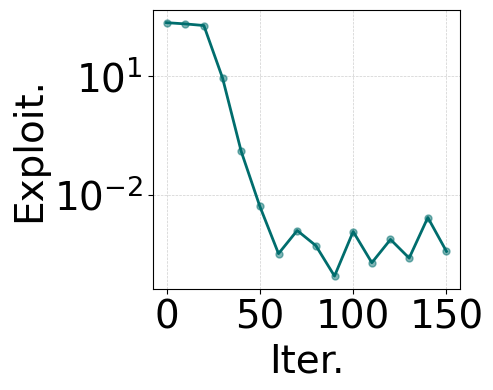

In [6]:
fig = bmfg.plot_exploitability(exploitabilities, log_scale=True, return_fig=True)

## 4. Final mean field and policy

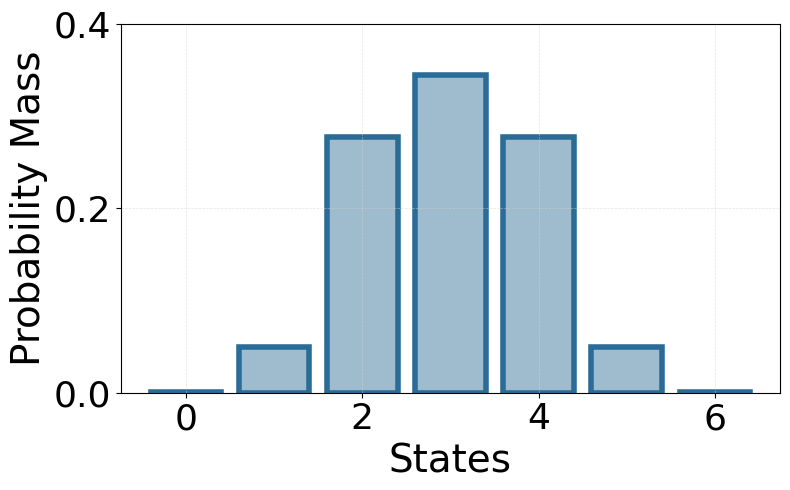

In [7]:
fig = bmfg.plot_mean_field(mean_field, is_grid=False, return_fig=True)

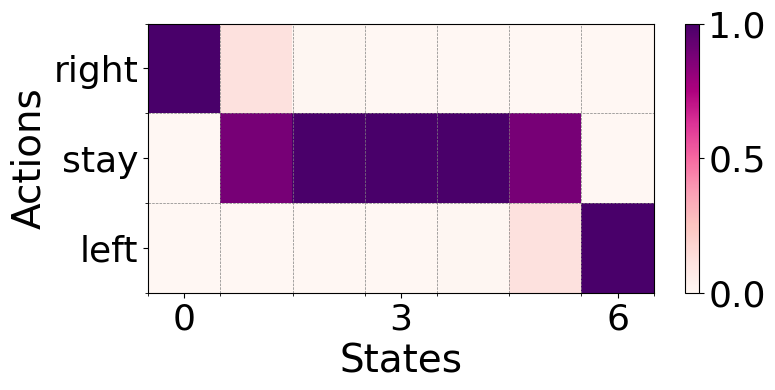

In [8]:
fig = bmfg.plot_policy(policy, action_labels=["left", "stay", "right"], return_fig=True)

## 5. How the mean field and the policy evolve

`bmfg.plot_gif` writes one GIF frame per iteration (`every=5` keeps every fifth one).

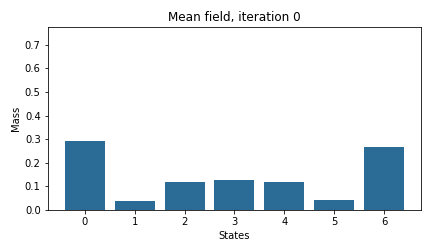

In [9]:
gif = bmfg.plot_gif(history.mean_fields, "gifs/mean_field.gif", kind="mean_field", every=5)
display(Image(filename=gif))

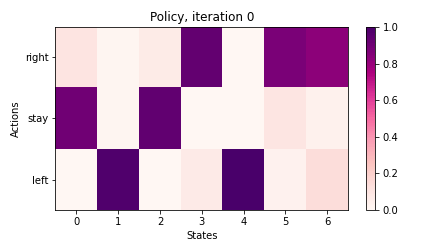

In [10]:
gif = bmfg.plot_gif(
    history.policies,
    "gifs/policy.gif",
    kind="policy",
    every=5,
    action_labels=["left", "stay", "right"],
)
display(Image(filename=gif))